# Partie de Ghada — VAR, Granger, Johansen/VECM, GARCH et Prophet

**Projet WattIf (consommation électrique française, 2016 → 31 août 2026).**
Ce notebook couvre les sections 3.2 (VAR + causalité de Granger), 3.3 (Johansen + VECM) et 4.3 (GARCH + Prophet) du rapport.

## Protocole commun 
- Cible : `conso_gwh` (GWh/jour). Données : `data/daily.csv` , jamais modifiées.
- Découpage chronologique 90/10 : 3 506 jours d'apprentissage (jusqu'au 6 août 2025), 390 jours de test (7 août 2025 → 31 août 2026). Jamais de k-fold.
- Les 56 derniers jours de l'apprentissage servent de **validation interne** pour départager des candidats ; le test n'est jamais utilisé pour choisir.
- Évaluation par blocs de 7 jours (h = 7) : à chaque origine, les paramètres restent **fixes** et seules les observations déjà connues sont ajoutées ; on prévoit les 7 jours suivants.
- Mêmes métriques pour tous : MSE, RMSE, MAE, MAPE, plus couverture et largeur de l'intervalle à 95 %.
- Diagnostic obligatoire pour chaque modèle : Ljung-Box (autocorrélation), Jarque-Bera (normalité), ARCH-LM (variance non constante).
- Reproductibilité : seed = 42, versions listées ci-dessous, chemins relatifs (à lancer depuis la racine du dépôt).

In [1]:
import logging, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy, statsmodels, arch, prophet
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen, select_order as vecm_select_order
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from arch import arch_model
from prophet import Prophet
from IPython.display import display

warnings.filterwarnings('ignore')          # les avertissements de convergence/tables sont gérés explicitement plus bas
for _name in ('cmdstanpy', 'prophet'):
    _lg = logging.getLogger(_name); _lg.handlers = [logging.NullHandler()]; _lg.propagate = False; _lg.setLevel(logging.CRITICAL)

SEED = 42
np.random.seed(SEED)
HORIZON, VALIDATION_DAYS, ALPHA = 7, 56, 0.05
FIG, EXP, FC = Path('figures/ghada'), Path('exports/ghada'), Path('forecasts')
for d in (FIG, EXP, FC):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})

print('Python', platform.python_version())
for name, mod in [('numpy', np), ('pandas', pd), ('scipy', scipy), ('statsmodels', statsmodels), ('arch', arch), ('prophet', prophet)]:
    print(f'{name:12s}', mod.__version__)

Importing plotly failed. Interactive plots will not work.


Python 3.11.5
numpy        1.26.4
pandas       3.0.6
scipy        1.17.1
statsmodels  0.15.0
arch         8.0.0
prophet      1.5.0


## Étape 0 — Chargement et découpage
On réutilise **exactement** le découpage de Yosra (`int(0.9 × n)` jours pour l'apprentissage), afin que tous les modèles soient comparables.
Le jeu de validation interne (56 jours = 8 semaines) est pris à la fin de l'apprentissage ; il sert uniquement à choisir entre candidats.

In [2]:
df = pd.read_csv('data/daily.csv', parse_dates=['date']).set_index('date').asfreq('D')
assert df[['conso_gwh', 'temp_moy', 'ferie']].notna().all().all(), 'valeurs manquantes inattendues'
n_train = int(len(df) * 0.9)
dev, test = df.iloc[:n_train], df.iloc[n_train:]            # apprentissage / test externe
est, valid = dev.iloc[:-VALIDATION_DAYS], dev.iloc[-VALIDATION_DAYS:]   # estimation / validation interne
assert est.index[-1] < valid.index[0] < test.index[0] and len(valid) % HORIZON == 0
for label, part in [('Estimation', est), ('Validation interne', valid), ('Test externe', test)]:
    print(f'{label:20s}{len(part):5d} jours  {part.index[0].date()} → {part.index[-1].date()}')

Estimation           3450 jours  2016-01-01 → 2025-06-11
Validation interne     56 jours  2025-06-12 → 2025-08-06
Test externe          390 jours  2025-08-07 → 2026-08-31


## Étape 1 — Variables déterministes (calendrier)
La consommation a un cycle **hebdomadaire** (week-end plus bas) et un cycle **annuel** (chauffage). Un VAR « nu » devrait les apprendre avec des retards, ce qui est très coûteux (il faudrait ~365 retards).
On les traite donc comme des **régresseurs exogènes connus à l'avance** : jours de la semaine (6 indicatrices), jour férié (`ferie`, donné par Fayfa) et 3 harmoniques de Fourier annuelles.
Ces variables sont du calendrier : les connaître pour le futur n'est **pas** de la triche. La température, elle, reste **endogène** (on ne connaît pas la météo future), le modèle doit donc la prévoir lui-même.

In [3]:
T0 = pd.Timestamp('2016-01-01')
FERIE = df['ferie']

def build_exog(idx, k_fourier=3):
    """Calendrier : Fourier annuel + jours de semaine + férié (0 si date future hors fichier)."""
    d = (idx - T0).days.to_numpy()
    X = pd.DataFrame(index=idx)
    for k in range(1, k_fourier + 1):
        X[f'sin{k}'] = np.sin(2 * np.pi * k * d / 365.25)
        X[f'cos{k}'] = np.cos(2 * np.pi * k * d / 365.25)
    for j in range(1, 7):
        X[f'dow{j}'] = (idx.dayofweek == j).astype(float)
    X['ferie'] = FERIE.reindex(idx).fillna(0).to_numpy()
    return X

X_all = build_exog(df.index)
ENDOG = ['conso_gwh', 'temp_moy']
Y_all = df[ENDOG]
print(X_all.shape, list(X_all.columns))

(3896, 13) ['sin1', 'cos1', 'sin2', 'cos2', 'sin3', 'cos3', 'dow1', 'dow2', 'dow3', 'dow4', 'dow5', 'dow6', 'ferie']


## Étape 2 — Stationnarité des deux variables (rappel pour VAR/VECM)
- ADF : H0 = racine unitaire (non stationnaire). KPSS : H0 = stationnaire. On conclut « stationnaire » si ADF rejette **et** KPSS ne rejette pas.
- Pourquoi c'est crucial : un **VAR** exige des séries stationnaires ; un **VECM** n'a de sens que si les séries sont **intégrées d'ordre 1** (I(1)) et cointégrées.

In [4]:
def stationarity_table(frame):
    rows = []
    for col in frame:
        s = frame[col].dropna()
        a = adfuller(s, regression='c', autolag='AIC')
        k = kpss(s, regression='c', nlags='auto')
        rows.append({'série': col, 'ADF stat': a[0], 'ADF p': a[1], 'KPSS stat': k[0], 'KPSS p (≥0,10 = non rejet)': k[1],
                     'conclusion': 'stationnaire' if (a[1] < .05 and k[1] >= .05) else ('limite' if a[1] < .05 else 'non stationnaire')})
    return pd.DataFrame(rows).set_index('série').round(4)

stat_levels = stationarity_table(dev[ENDOG])
stat_diff = stationarity_table(dev[ENDOG].diff().dropna()).rename(index=lambda s: 'Δ ' + s)
stat_tab = pd.concat([stat_levels, stat_diff])
display(stat_tab)
stat_tab.to_csv(EXP / 'stationnarite_var_vecm.csv')

,ADF stat,ADF p,KPSS stat,"KPSS p (≥0,10 = non rejet)",conclusion
série,,,,,
conso_gwh,-4.1012,0.0010,0.4029,0.0759,stationnaire
temp_moy,-3.4782,0.0086,0.0751,0.1000,stationnaire
Δ conso_gwh,-12.2070,0.0000,0.0160,0.1000,stationnaire
Δ temp_moy,-19.3488,0.0000,0.0176,0.1000,stationnaire


### Lecture
ADF rejette la racine unitaire pour les deux séries brutes (p = 0,001 pour la consommation, 0,009 pour la température) et KPSS ne rejette pas la stationnarité à 5 % (p = 0,076 et ≥ 0,10). Les deux séries sont donc **stationnaires en niveau** (cas limite pour la consommation : KPSS la rejetterait à 10 %). Les différences premières sont, sans surprise, stationnaires aussi.
**Conséquences.** (1) On estime le VAR **en niveaux**, sans différencier, avec le calendrier en exogène. (2) Le VECM sera formellement fragile : il suppose des séries I(1) (étape 10).

## Étape 3 — VAR : choix de l'ordre p par AIC / BIC
Un VAR(p) régresse chaque variable sur p retards des **deux** variables. Choisir p :
- **AIC** : récompense l'ajustement, pénalise peu les paramètres → ordre souvent grand.
- **BIC / HQIC** : pénalisent davantage → ordre plus petit, plus parcimonieux.
On calcule les critères sur l'échantillon d'estimation (la validation interne reste vierge).

Ordres retenus par critère : {'aic': 13, 'bic': 3, 'hqic': 9, 'fpe': 13}


,aic,bic,hqic,fpe
1,7.6451,7.7024,7.6656,2090.4502
2,7.4665,7.5310,7.4895,1748.5029
3,7.4412,7.5128,7.4668,1704.8168
5,7.4362,7.5222,7.4669,1696.3341
7,7.4319,7.5322,7.4677,1688.9975
9,7.4116,7.5262,7.4525,1655.0398
13,7.4087,7.5519,7.4598,1650.2232
14,7.4102,7.5606,7.4639,1652.7174
21,7.4142,7.6148,7.4859,1659.4561


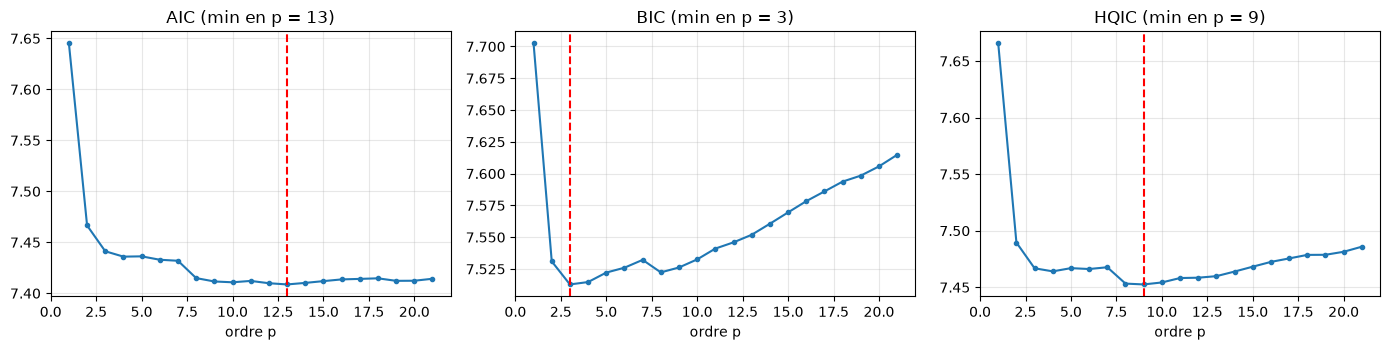

In [5]:
sel = VAR(est[ENDOG], exog=X_all.loc[est.index]).select_order(maxlags=21)
ic = pd.DataFrame(sel.ics, index=range(0, 22))[['aic', 'bic', 'hqic', 'fpe']]
selected = {k: int(v) for k, v in sel.selected_orders.items()}
print('Ordres retenus par critère :', selected)
display(ic.loc[[1, 2, 3, 5, 7, 9, 13, 14, 21]].round(4))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, c in zip(ax, ['aic', 'bic', 'hqic']):
    a.plot(ic.index[1:], ic[c].iloc[1:], marker='o', ms=3); a.axvline(selected[c], color='r', ls='--')
    a.set_title(f'{c.upper()} (min en p = {selected[c]})'); a.set_xlabel('ordre p')
plt.tight_layout(); fig.savefig(FIG / 'var_criteres_ordre.png', bbox_inches='tight'); plt.show()
ic.round(5).to_csv(EXP / 'var_criteres_ordre.csv')

### Lecture
Les critères désignent des ordres très différents : **BIC → 3**, HQIC → 9, **AIC → 13**. La courbe montre pourquoi : le gain d'AIC est énorme de p = 1 à p = 3 (7,645 → 7,441), puis quasi nul (7,409 à p = 13). L'AIC, qui pénalise peu les paramètres, continue de grappiller des miettes ; le BIC s'arrête dès que le gain devient négligeable.

## Étape 4 — Outils communs : diagnostics, métriques, prévision glissante
Les fonctions ci-dessous servent à **tous** les modèles de ce notebook (règles communes 1 et 2).

In [6]:
def diagnostics(resid, label, lags=(7, 14), model_df=0, arch_lags=7):
    """Ljung-Box, Jarque-Bera et ARCH-LM sur une série de résidus (ou résidus standardisés)."""
    r = pd.Series(np.asarray(resid, dtype=float)).dropna()
    lb = acorr_ljungbox(r, lags=list(lags), model_df=model_df, return_df=True)
    jb, jb_p, skew, kurt = jarque_bera(r)
    lm, lm_p, _, _ = het_arch(r, nlags=arch_lags)
    row = {'modèle/série': label, 'n': len(r)}
    for l in lags:
        row[f'LB p (h={l})'] = lb.loc[l, 'lb_pvalue']
    row.update({'JB p': jb_p, 'asymétrie': skew, 'kurtosis': kurt, 'ARCH-LM p': lm_p})
    return row

def forecast_metrics(pred):
    e = pred['observe'] - pred['prevision']
    out = {'n': len(pred), 'MSE': np.mean(e**2), 'RMSE': np.sqrt(np.mean(e**2)), 'MAE': np.mean(np.abs(e)),
           'MAPE (%)': 100 * np.mean(np.abs(e / pred['observe'])), 'biais': -np.mean(e)}
    if 'borne_inferieure_95' in pred and pred['borne_inferieure_95'].notna().all():
        inside = (pred['observe'] >= pred['borne_inferieure_95']) & (pred['observe'] <= pred['borne_superieure_95'])
        out.update({'couverture_95': inside.mean(), 'largeur_moy_95': (pred['borne_superieure_95'] - pred['borne_inferieure_95']).mean()})
    return out

COLS = ['origine', 'date', 'horizon', 'observe', 'prevision', 'borne_inferieure_95', 'borne_superieure_95']
def to_frame(rows):
    return pd.DataFrame(rows, columns=COLS)

## Étape 5 — VAR : prévision glissante et choix entre les ordres AIC/BIC
Candidats = ordres choisis par AIC, BIC et HQIC. Règle de sélection (écrite **avant** de voir le test, comme pour le SARIMA) :
*RMSE minimale en validation interne (8 blocs de 7 jours)*. La prévision de la température est faite par le VAR lui-même (pas de météo future).

In [7]:
def wf_var(res, endog, X, start, end, h=HORIZON):
    """Prévisions glissantes : paramètres fixes, historique réel mis à jour à chaque bloc."""
    rows, k = [], res.k_ar
    for s in range(start, end, h):
        e = min(s + h, end); steps = e - s
        hist = endog.iloc[s - k:s].to_numpy()
        fc, lo, hi = res.forecast_interval(hist, steps=steps, alpha=ALPHA, exog_future=X.iloc[s:e].to_numpy())
        for j in range(steps):
            rows.append((endog.index[s - 1], endog.index[s + j], j + 1, endog['conso_gwh'].iloc[s + j], fc[j, 0], lo[j, 0], hi[j, 0]))
    return to_frame(rows)

n_est = len(est)
cand_orders = sorted(set(selected[c] for c in ['aic', 'bic', 'hqic']))
var_val_rows = []
for p in cand_orders:
    res_p = VAR(est[ENDOG], exog=X_all.loc[est.index]).fit(p)
    pr = wf_var(res_p, Y_all, X_all, n_est, n_train)
    m = forecast_metrics(pr)
    var_val_rows.append({'ordre p': p, 'AIC': res_p.aic, 'BIC': res_p.bic, 'RMSE validation': m['RMSE'], 'MAE validation': m['MAE'], 'stable': res_p.is_stable()})
var_val = pd.DataFrame(var_val_rows).set_index('ordre p')
display(var_val.round(3))
P_VAR = int(var_val['RMSE validation'].idxmin())
print('Ordre VAR retenu (RMSE de validation minimale) :', P_VAR)
var_val.to_csv(EXP / 'var_validation_interne.csv')

,AIC,BIC,RMSE validation,MAE validation,stable
ordre p,,,,,
3,7.440,7.511,48.366,38.661,True
9,7.410,7.524,48.527,36.432,True
13,7.408,7.551,48.738,37.496,True


Ordre VAR retenu (RMSE de validation minimale) : 3


### Lecture
Les trois ordres candidats ont des RMSE de validation presque identiques (48,4 / 48,5 / 48,7 GWh) : la différence n'est pas significative sur 8 semaines. On applique la règle écrite à l'avance → **VAR(3)**, qui est aussi le plus parcimonieux. Tous sont stables.

## Étape 6 — VAR final : estimation, stabilité et diagnostics des résidus
On ré-estime le VAR retenu sur **tout l'apprentissage** (3 506 jours). Vérifications :
- **Stabilité** : toutes les racines du polynôme caractéristique de module < 1 (sinon prévisions explosives).
- **Résidus** : Ljung-Box (blancheur), Jarque-Bera (normalité), ARCH-LM — équation par équation, puis tests multivariés.

Modèle : VAR(3) avec exogènes calendrier ; stable = True ; module max des racines = 0.2548


,n,LB p (h=7),LB p (h=14),JB p,asymétrie,kurtosis,ARCH-LM p
modèle/série,,,,,,,
VAR(3) — éq. conso_gwh,3503,0.0000,0.0000,0.0,0.4102,5.7862,0.0000
VAR(3) — éq. temp_moy,3503,0.1287,0.0791,0.0,-0.1107,3.4771,0.0006


Portmanteau multivarié (14 retards) : stat = 351.1, p = 1.731e-49
Normalité multivariée (Jarque-Bera) : stat = 1268.3, p = 2.533e-273
Matrice de corrélation des résidus :


,conso_gwh,temp_moy
conso_gwh,1.000,-0.463
temp_moy,-0.463,1.000


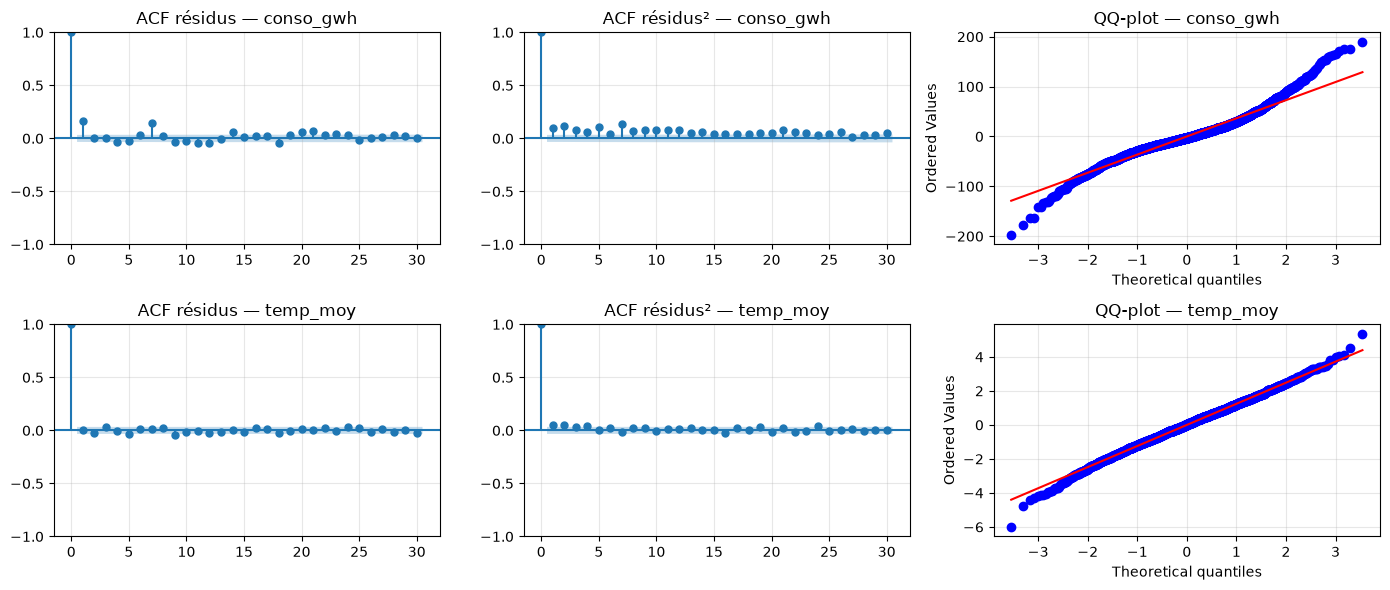

In [8]:
var_res = VAR(dev[ENDOG], exog=X_all.loc[dev.index]).fit(P_VAR)
print('Modèle : VAR(%d) avec exogènes calendrier ; stable =' % P_VAR, var_res.is_stable(), '; module max des racines =', round(float(np.max(np.abs(var_res.roots))) ** -1, 4))
resid = var_res.resid
diag_var = pd.DataFrame([diagnostics(resid[c], f'VAR({P_VAR}) — éq. {c}') for c in ENDOG]).set_index('modèle/série')
display(diag_var.round(4))
wh = var_res.test_whiteness(nlags=14, adjusted=True)
nm = var_res.test_normality()
print(f'Portmanteau multivarié (14 retards) : stat = {wh.test_statistic:.1f}, p = {wh.pvalue:.4g}')
print(f'Normalité multivariée (Jarque-Bera) : stat = {nm.test_statistic:.1f}, p = {nm.pvalue:.4g}')
print('Matrice de corrélation des résidus :'); display(resid.corr().round(3))
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for i, c in enumerate(ENDOG):
    plot_acf(resid[c], lags=30, ax=ax[i, 0], title=f'ACF résidus — {c}')
    plot_acf(resid[c] ** 2, lags=30, ax=ax[i, 1], title=f'ACF résidus² — {c}')
    stats.probplot(resid[c], dist='norm', plot=ax[i, 2]); ax[i, 2].set_title(f'QQ-plot — {c}')
plt.tight_layout(); fig.savefig(FIG / 'var_diagnostics_residus.png', bbox_inches='tight'); plt.show()
diag_var.to_csv(EXP / 'var_diagnostics.csv')

### Lecture des diagnostics du VAR(3)
- **Stabilité** : OK (toutes les racines hors du disque unité).
- **Équation température** : résidus propres (Ljung-Box p = 0,13 à h = 7 ; QQ-plot proche de la droite).
- **Équation consommation** : Ljung-Box rejette très fortement (p ≈ 10⁻³⁵) : il reste de l'autocorrélation, visible sur l'ACF aux retards 1 et 7 (≈ 0,15). Le VAR(3) ne capte pas la structure hebdomadaire fine (retards 7 et 8, cf. étape 12).
- **Normalité** : Jarque-Bera rejette (kurtosis 5,8) ; le QQ-plot montre des queues épaisses : jours exceptionnels (vagues de froid, confinements).
- **ARCH-LM** rejette (p ≈ 10⁻³²) et l'ACF des résidus² est positive : la variance n'est pas constante → c'est ce qui motive le GARCH (4.3).
**Conséquence** : les intervalles gaussiens du VAR sont à prendre avec prudence ; on vérifiera leur couverture réelle sur le test.

## Étape 7 — Causalité de Granger
**Idée.** X « cause au sens de Granger » Y si les retards de X améliorent la prévision de Y, une fois les retards de Y pris en compte.
Test de Fisher : H0 = *tous les coefficients des retards de X dans l'équation de Y sont nuls*. p < 0,05 → on rejette H0.
⚠️ C'est une causalité **prédictive**, pas physique. On teste les deux sens et on vérifie la robustesse à l'ordre p.

In [9]:
def granger_row(res, caused, causing):
    t = res.test_causality(caused, [causing], kind='f')
    return {'hypothèse': f'{causing} → {caused}', 'F': t.test_statistic, 'p-value': t.pvalue, 'ddl': str(t.df), 'rejet H0 (5 %)': t.pvalue < .05}

granger = pd.DataFrame([granger_row(var_res, 'conso_gwh', 'temp_moy'), granger_row(var_res, 'temp_moy', 'conso_gwh')])
display(granger.round(6))
inst = var_res.test_inst_causality('conso_gwh')
print(f'Causalité instantanée (corrélation des chocs du même jour) : stat = {inst.test_statistic:.1f}, p = {inst.pvalue:.3g}')
rob = []
for p in sorted(set(cand_orders + [1, 7])):
    r = VAR(dev[ENDOG], exog=X_all.loc[dev.index]).fit(p)
    rob.append({'ordre p': p, 'p(temp→conso)': r.test_causality('conso_gwh', ['temp_moy']).pvalue, 'p(conso→temp)': r.test_causality('temp_moy', ['conso_gwh']).pvalue})
rob = pd.DataFrame(rob).set_index('ordre p')
display(rob)
granger.to_csv(EXP / 'granger.csv', index=False); rob.to_csv(EXP / 'granger_robustesse_ordre.csv')

,hypothèse,F,p-value,ddl,rejet H0 (5 %)
0,temp_moy → conso_gwh,118.573262,0.000000,"(3, 6966)",True
1,conso_gwh → temp_moy,6.606090,0.000187,"(3, 6966)",True


Causalité instantanée (corrélation des chocs du même jour) : stat = 618.1, p = 1.99e-136


,p(temp→conso),p(conso→temp)
ordre p,,
1,3.834979e-35,0.026425
3,6.790902e-75,0.000187
7,1.288527e-76,0.000988
9,3.783647e-78,0.000156
13,1.902616e-74,0.000049


### Lecture
- **Température → consommation** : F = 118,6, p ≈ 7·10⁻⁷⁵ → rejet net. Robuste à tous les ordres testés (p < 10⁻³⁴ de p = 1 à p = 13). Les retards de température améliorent fortement la prévision de la consommation (relation de chauffage).
- **Consommation → température** : F = 6,6, p = 0,0002 → rejet aussi, mais la statistique est **18 fois plus faible** (et p varie de 0,026 à 5·10⁻⁵ selon l'ordre).
- **Instantanée** : les chocs du même jour sont corrélés à −0,46 (p ≈ 10⁻¹³⁶) : un jour plus chaud que prévu est un jour de moindre consommation.
**Prudence.** Granger mesure une causalité *prédictive*, pas physique : la consommation ne fait évidemment pas la météo. Le sens inverse significatif est probablement un artefact (hypothèses : la température moyenne nationale est une mesure imparfaite de la météo réellement ressentie, que la consommation reflète ; puissance du test sur 3 506 jours, qui rend significatifs de très petits effets). On retient surtout l'**asymétrie** : le sens physique domine.

## Étape 8 — Fonctions de réponse impulsionnelle (IRF)
Question concrète : *si la température est 1 écart-type plus basse que prévu aujourd'hui, de combien (et combien de temps) la consommation réagit-elle ?*
Pour les IRF orthogonalisées (décomposition de Cholesky), l'**ordre** des variables compte : on met la température en premier (un choc de consommation ne peut pas changer la météo le jour même, l'inverse oui).

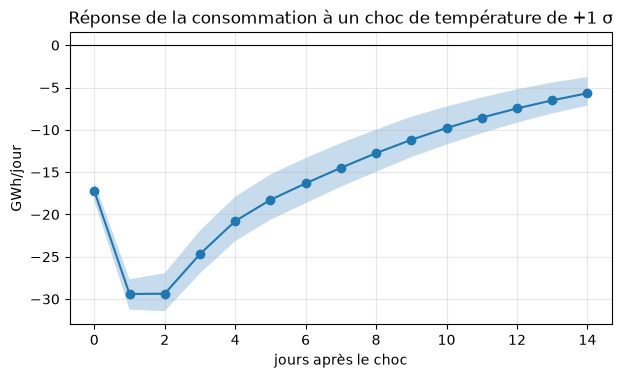

σ du choc de température = 1.25 °C ; réponse de la consommation (GWh/jour) aux jours 0 à 7 : [-17.2 -29.4 -29.4 -24.7 -20.8 -18.3 -16.3 -14.5]
Pic de la réponse : -29.4 GWh au jour 1 (soit -23.6 GWh par °C) ; bande à 95 % au pic : [-31.2 ; -27.7]


In [10]:
var_irf = VAR(dev[['temp_moy', 'conso_gwh']], exog=X_all.loc[dev.index]).fit(P_VAR)
irf = var_irf.irf(14)
resp = irf.orth_irfs[:, 1, 0]                       # réponse de conso (1) à un choc de temp (0)
lo_i, hi_i = irf.errband_mc(orth=True, repl=500, signif=.05, seed=SEED)
band_lo, band_hi = lo_i[:, 1, 0], hi_i[:, 1, 0]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(resp, marker='o'); ax.fill_between(range(len(resp)), band_lo, band_hi, alpha=.25); ax.axhline(0, color='k', lw=.8)
ax.set_xlabel('jours après le choc'); ax.set_ylabel('GWh/jour'); ax.set_title('Réponse de la consommation à un choc de température de +1 σ')
fig.savefig(FIG / 'var_irf_temp_conso.png', bbox_inches='tight'); plt.show()
sd_temp = float(np.sqrt(var_irf.sigma_u.iloc[0, 0]))
k_pic = int(np.argmax(np.abs(resp)))
print(f'σ du choc de température = {sd_temp:.2f} °C ; réponse de la consommation (GWh/jour) aux jours 0 à 7 :', np.round(resp[:8], 1))
print(f'Pic de la réponse : {resp[k_pic]:.1f} GWh au jour {k_pic} (soit {resp[k_pic] / sd_temp:.1f} GWh par °C) ; bande à 95 % au pic : [{band_lo[k_pic]:.1f} ; {band_hi[k_pic]:.1f}]')
pd.DataFrame({'jour': range(len(resp)), 'irf': resp, 'bas_95': band_lo, 'haut_95': band_hi}).to_csv(EXP / 'var_irf.csv', index=False)

### Lecture de la réponse impulsionnelle
Un choc de température de +1 σ (≈ +1,25 °C par rapport à la prévision du VAR) fait baisser la consommation de **17 GWh le jour même**, puis de **29 GWh au pic (jours 1 à 2)** (≈ −24 GWh par °C de choc), et l'effet décroît lentement (−14,5 GWh au jour 7) : inertie des bâtiments et persistance de la météo. La bande à 95 % est étroite. Cet effet moyen annuel est plus faible que la pente hivernale de l'EDA (≈ 56 GWh/°C sous 15 °C) car il inclut l'été, où il n'y a pas de chauffage.

## Étape 9 — Prévision glissante du VAR sur le test externe
Modèle figé sur l'apprentissage, 56 blocs de 7 jours (le dernier fait 5 jours : 390 = 55×7 + 5).

In [11]:
pred_var = wf_var(var_res, Y_all, X_all, n_train, len(df))
assert len(pred_var) == len(test) and pred_var['date'].tolist() == list(test.index)
print({k: round(v, 3) for k, v in forecast_metrics(pred_var).items()})

{'n': 390, 'MSE': 6234.262, 'RMSE': 78.957, 'MAE': 54.67, 'MAPE (%)': 4.306, 'biais': 3.052, 'couverture_95': 0.931, 'largeur_moy_95': 277.975}


## Étape 10 — Johansen : y a-t-il cointégration ?
**Cointégration** : deux séries I(1) peuvent dériver séparément mais rester liées par une combinaison stationnaire (un « équilibre à long terme »). Le test de Johansen compte le **rang de cointégration** r parmi k = 2 variables :
- r = 0 : pas de cointégration → VAR en différences ;
- r = 1 : un équilibre de long terme → **VECM** ;
- r = 2 (rang plein) : les deux séries sont déjà **stationnaires** → un VAR en niveaux suffit, la notion de cointégration est triviale.
Le test suppose des séries I(1). Notre étape 2 a déjà montré que ce n'est probablement pas le cas : on le vérifie sur les données brutes **et** sur des données corrigées du calendrier.

In [12]:
vecm_ord = vecm_select_order(dev[ENDOG], maxlags=14, deterministic='co', exog=X_all.loc[dev.index])
K_sel = {c: int(v) for c, v in vecm_ord.selected_orders.items()}
print('Retards en différences (k_ar_diff) choisis par critère (VECM, constante, exogènes calendrier) :', K_sel)

def johansen_table(frame, det_order, k):
    j = coint_johansen(frame, det_order=det_order, k_ar_diff=k)
    rows = []
    for r in range(2):
        rows.append({'H0': f'r ≤ {r}', 'trace': j.lr1[r], 'crit 95 % (trace)': j.cvt[r, 1], 'rejet (trace)': j.lr1[r] > j.cvt[r, 1],
                     'λ-max': j.lr2[r], 'crit 95 % (λ-max)': j.cvm[r, 1], 'rejet (λ-max)': j.lr2[r] > j.cvm[r, 1]})
    return pd.DataFrame(rows).set_index('H0')

def rank_from(tab, col='rejet (trace)'):
    return int(tab[col].sum())   # nombre d'hypothèses r ≤ i rejetées en séquence

K_J = K_sel['bic'] if K_sel['bic'] >= 1 else 1
# Séries « désaisonnalisées » : résidus de la régression de chaque niveau sur le calendrier (apprentissage uniquement)
adj = pd.DataFrame({c: sm.OLS(dev[c], sm.add_constant(X_all.loc[dev.index])).fit().resid for c in ENDOG})
print(f'\n— Données brutes, constante, k_ar_diff = {K_J} —'); tab_raw = johansen_table(dev[ENDOG], 0, K_J); display(tab_raw.round(2))
print(f'— Données corrigées du calendrier, constante, k_ar_diff = {K_J} —'); tab_adj = johansen_table(adj, 0, K_J); display(tab_adj.round(2))
sens = []
for name, frame in [('brutes', dev[ENDOG]), ('corrigées calendrier', adj)]:
    for det in [-1, 0, 1]:
        for k in sorted(set([1, 2, K_J, 7, 13])):
            t = johansen_table(frame, det, k)
            sens.append({'données': name, 'det_order': det, 'k_ar_diff': k, 'rang (trace)': rank_from(t), 'rang (λ-max)': rank_from(t, 'rejet (λ-max)')})
sens = pd.DataFrame(sens)
display(sens.pivot_table(index=['données', 'det_order'], columns='k_ar_diff', values='rang (trace)'))
tab_raw.to_csv(EXP / 'johansen_brut.csv'); tab_adj.to_csv(EXP / 'johansen_corrige_calendrier.csv'); sens.to_csv(EXP / 'johansen_sensibilite.csv', index=False)
print('\nStationnarité des données corrigées du calendrier :'); display(stationarity_table(adj))

Retards en différences (k_ar_diff) choisis par critère (VECM, constante, exogènes calendrier) : {'aic': 12, 'bic': 2, 'hqic': 8, 'fpe': 12}

— Données brutes, constante, k_ar_diff = 2 —


,trace,crit 95 % (trace),rejet (trace),λ-max,crit 95 % (λ-max),rejet (λ-max)
H0,,,,,,
r ≤ 0,337.72,15.49,True,298.17,14.26,True
r ≤ 1,39.55,3.84,True,39.55,3.84,True


— Données corrigées du calendrier, constante, k_ar_diff = 2 —


,trace,crit 95 % (trace),rejet (trace),λ-max,crit 95 % (λ-max),rejet (λ-max)
H0,,,,,,
r ≤ 0,577.73,15.49,True,399.39,14.26,True
r ≤ 1,178.34,3.84,True,178.34,3.84,True


k_ar_diff                        1    2    7    13
données              det_order                    
brutes               -1         1.0  1.0  1.0  1.0
                      0         2.0  2.0  2.0  2.0
                      1         2.0  2.0  2.0  2.0
corrigées calendrier -1         2.0  2.0  2.0  2.0
                      0         2.0  2.0  2.0  2.0
                      1         2.0  2.0  2.0  2.0


Stationnarité des données corrigées du calendrier :


,ADF stat,ADF p,KPSS stat,"KPSS p (≥0,10 = non rejet)",conclusion
série,,,,,
conso_gwh,-8.2885,0.0,3.7352,0.01,limite
temp_moy,-16.3403,0.0,0.7605,0.01,limite


### Lecture du test de Johansen
Le **rang est 2 (rang plein)** pour toutes les spécifications raisonnables : on rejette à la fois « r ≤ 0 » et « r ≤ 1 » (statistiques de trace 337,7 et 39,6, très au-dessus des seuils 15,5 et 3,8), que l'on prenne 1 à 13 retards, une constante ou une tendance, des données brutes ou corrigées du calendrier. Le seul cas qui donne r = 1 est la spécification **sans constante** sur données brutes, inadaptée ici (la consommation moyenne est de 1 254 GWh : une constante est indispensable).
**Interprétation.** Rang plein = les deux séries sont déjà **stationnaires** (cohérent avec l'ADF de l'étape 2) : il n'y a pas de tendance stochastique commune à « cointégrer ». Il n'y a donc **pas de cointégration au sens strict** et un VAR en niveaux suffit. (Les séries corrigées du calendrier ont un KPSS qui rejette — ruptures de niveau 2020 et 2022 — mais l'ADF rejette très fortement la racine unitaire : cas limite qui ne change pas la conclusion.)
**Pour le VECM** : on l'estime quand même avec r = 1, comme demandé, mais il faudra relire ses résultats avec cette réserve.

## Étape 11 — VECM : estimation et vitesse de correction
Le sujet demande un VECM avec interprétation de la vitesse de correction. On l'estime donc avec **r = 1** (une relation d'équilibre conso–température), en **signalant** que ce choix est imposé : le test de l'étape 10 ne le soutient pas formellement.
Équation du VECM : Δy_t = α·(β′y_{t−1}) + Σ Γ_i Δy_{t−i} + constante + calendrier + u_t.
- **β** = relation d'équilibre (normalisée : coefficient de `conso_gwh` = 1) ;
- **α** = *vitesse de correction* : part de l'écart à l'équilibre résorbée **chaque jour**. Demi-vie = ln(0,5) / ln(1 + α_conso).
Même règle de sélection du nombre de retards que pour le VAR (validation interne).

In [13]:
def fit_vecm(frame, k, exog):
    return VECM(frame, exog=exog, k_ar_diff=k, coint_rank=1, deterministic='co').fit()

def vecm_forecast_block(res, endog, X, s, steps):
    """Récurrence du VECM à paramètres fixes depuis l'origine s−1 ; intervalle via la représentation MA."""
    p, K = res.k_ar, res.neqs
    hist = endog.iloc[s - p:s].to_numpy().copy()
    path = []
    for j in range(steps):
        y_prev = hist[-1]
        dy = res.alpha @ (res.beta.T @ y_prev)
        for i in range(1, p):
            dy = dy + res.gamma[:, (i - 1) * K:i * K] @ (hist[-i] - hist[-i - 1])
        dy = dy + res.det_coef @ np.r_[1.0, X.iloc[s + j].to_numpy()]
        hist = np.vstack([hist, y_prev + dy]); path.append(y_prev + dy)
    path = np.array(path)
    phi = res.ma_rep(steps)
    var_h = np.cumsum([np.diag(phi[i] @ res.sigma_u @ phi[i].T) for i in range(steps)], axis=0)
    se = np.sqrt(var_h)
    z = stats.norm.ppf(1 - ALPHA / 2)
    return path, path - z * se, path + z * se

def wf_vecm(res, endog, X, start, end, h=HORIZON):
    rows = []
    for s in range(start, end, h):
        steps = min(s + h, end) - s
        fc, lo, hi = vecm_forecast_block(res, endog, X, s, steps)
        for j in range(steps):
            rows.append((endog.index[s - 1], endog.index[s + j], j + 1, endog['conso_gwh'].iloc[s + j], fc[j, 0], lo[j, 0], hi[j, 0]))
    return to_frame(rows)

# Contrôle de la récurrence manuelle contre la méthode officielle de statsmodels (même modèle, même origine)
chk = fit_vecm(est[ENDOG], 2, X_all.loc[est.index])
mine, mlo, mhi = vecm_forecast_block(chk, Y_all, X_all, n_est, 7)
ref, rlo, rhi = chk.predict(steps=7, alpha=ALPHA, exog_fc=X_all.iloc[n_est:n_est + 7].to_numpy())
print('Écart max récurrence manuelle vs statsmodels : point =', float(np.abs(mine - ref).max()), '; bornes =', float(max(np.abs(mlo - rlo).max(), np.abs(mhi - rhi).max())))
assert np.allclose(mine, ref, atol=1e-6) and np.allclose(mlo, rlo, atol=1e-6) and np.allclose(mhi, rhi, atol=1e-6)

cand_k = sorted(set(K_sel[c] for c in ['aic', 'bic', 'hqic'] if K_sel[c] >= 1) | {2})
vecm_val_rows = []
for k in cand_k:
    r_k = fit_vecm(est[ENDOG], k, X_all.loc[est.index])
    m = forecast_metrics(wf_vecm(r_k, Y_all, X_all, n_est, n_train))
    vecm_val_rows.append({'k_ar_diff': k, 'RMSE validation': m['RMSE'], 'MAE validation': m['MAE'], 'alpha conso': float(r_k.alpha[0, 0])})
vecm_val = pd.DataFrame(vecm_val_rows).set_index('k_ar_diff')
display(vecm_val.round(4))
K_VECM = int(vecm_val['RMSE validation'].idxmin())
print('k_ar_diff retenu pour le VECM :', K_VECM)
vecm_val.to_csv(EXP / 'vecm_validation_interne.csv')

Écart max récurrence manuelle vs statsmodels : point = 2.2737367544323206e-13 ; bornes = 4.547473508864641e-13


,RMSE validation,MAE validation,alpha conso
k_ar_diff,,,
2,55.4823,44.9359,-0.0534
8,62.3750,39.4955,0.0044
12,53.4391,40.6228,-0.0222


k_ar_diff retenu pour le VECM : 12


              Loading coefficients (alpha) for equation temp_moy              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ec1           -0.0023      0.000    -10.974      0.000      -0.003      -0.002
          Cointegration relations for loading-coefficients-column 1           
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
beta.1         1.0000          0          0      0.000       1.000       1.000
beta.2        82.0777      4.469     18.368      0.000      73.320      90.836

Relation d'équilibre : conso + 82.08 × température = constante  (⇔ conso = c − 82.1 × T)
α_conso = -0.0181 (p = 0.0041) → 1.8 % de l'écart résorbé par jour ; demi-vie ≈ 37.9 jours
α_temp  = -0.0023 (p = 0)
Stationnarité du terme de correction (ADF p = 0.0003 )


,n,LB p (h=7),LB p (h=14),JB p,asymétrie,kurtosis,ARCH-LM p
modèle/série,,,,,,,
VECM — éq. conso_gwh,3493,0.0000,0.0,0.0,0.3641,5.7700,0.0
VECM — éq. temp_moy,3493,0.9998,1.0,0.0,-0.1047,3.4365,0.0


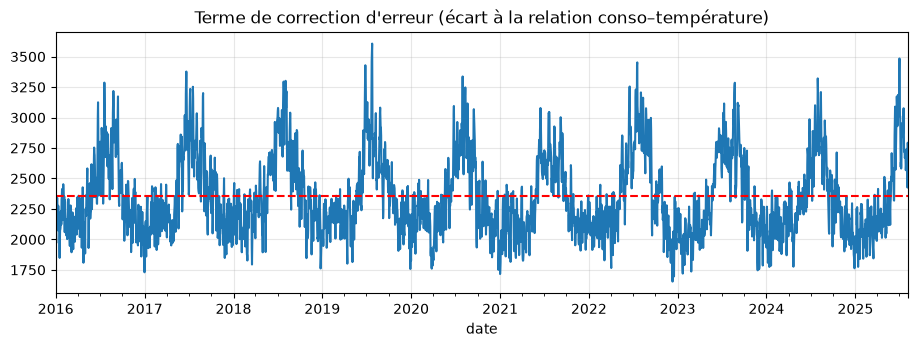


Robustesse de la vitesse de correction au nombre de retards :


,α_conso,p(α_conso),α_temp,β_temp,demi-vie (jours)
k_ar_diff,,,,,
2,-0.0522,0.0000,-0.0026,61.7661,12.9347
8,0.0072,0.0284,-0.0017,134.1016,NaN
12,-0.0181,0.0041,-0.0023,82.0777,37.9227


In [14]:
vecm_res = fit_vecm(dev[ENDOG], K_VECM, X_all.loc[dev.index])
print(vecm_res.summary().tables[-2]); print(vecm_res.summary().tables[-1])
alpha_c, alpha_t = float(vecm_res.alpha[0, 0]), float(vecm_res.alpha[1, 0])
beta_t = float(vecm_res.beta[1, 0])
p_alpha_c, p_alpha_t = float(vecm_res.pvalues_alpha[0, 0]), float(vecm_res.pvalues_alpha[1, 0])
half_life = np.log(.5) / np.log(1 + alpha_c)
ec = pd.Series(np.asarray(vecm_res.beta.T @ dev[ENDOG].to_numpy().T).ravel(), index=dev.index, name='écart à l\'équilibre')
print(f'\nRelation d\'équilibre : conso + {beta_t:.2f} × température = constante  (⇔ conso = c − {beta_t:.1f} × T)')
print(f'α_conso = {alpha_c:.4f} (p = {p_alpha_c:.3g}) → {abs(alpha_c)*100:.1f} % de l\'écart résorbé par jour ; demi-vie ≈ {half_life:.1f} jours')
print(f'α_temp  = {alpha_t:.4f} (p = {p_alpha_t:.3g})')
print('Stationnarité du terme de correction (ADF p =', round(adfuller(ec, autolag='AIC')[1], 4), ')')
diag_vecm = pd.DataFrame([diagnostics(vecm_res.resid[:, i], f'VECM — éq. {c}') for i, c in enumerate(ENDOG)]).set_index('modèle/série')
display(diag_vecm.round(4)); diag_vecm.to_csv(EXP / 'vecm_diagnostics.csv')
fig, ax = plt.subplots(figsize=(11, 3.4)); ec.plot(ax=ax); ax.axhline(ec.mean(), color='r', ls='--')
ax.set_title("Terme de correction d'erreur (écart à la relation conso–température)"); fig.savefig(FIG / 'vecm_terme_correction.png', bbox_inches='tight'); plt.show()
pd.Series({'k_ar_diff': K_VECM, 'rang_impose': 1, 'alpha_conso': alpha_c, 'p_alpha_conso': p_alpha_c, 'alpha_temp': alpha_t, 'p_alpha_temp': p_alpha_t,
           'beta_temp': beta_t, 'demi_vie_jours': half_life}).to_csv(EXP / 'vecm_parametres.csv', header=['valeur'])
rob_v = []
for k in sorted(set([2, 8, K_VECM])):
    r_k = fit_vecm(dev[ENDOG], k, X_all.loc[dev.index]); a = float(r_k.alpha[0, 0])
    rob_v.append({'k_ar_diff': k, 'α_conso': a, 'p(α_conso)': float(r_k.pvalues_alpha[0, 0]), 'α_temp': float(r_k.alpha[1, 0]),
                  'β_temp': float(r_k.beta[1, 0]), 'demi-vie (jours)': np.log(.5) / np.log(1 + a) if -1 < a < 0 else np.nan})
rob_v = pd.DataFrame(rob_v).set_index('k_ar_diff'); print('\nRobustesse de la vitesse de correction au nombre de retards :'); display(rob_v.round(4)); rob_v.to_csv(EXP / 'vecm_robustesse_retards.csv')

### Lecture du VECM
- **Relation d'équilibre** : conso = c − 82 × T. À long terme, un degré de plus fait baisser la consommation d'environ 82 GWh/jour (ordre de grandeur cohérent avec la pente de chauffage de l'EDA, ≈ 56 GWh/°C sous 15 °C).
- **Vitesse de correction** : α_conso = −0,018 (p = 0,004) → environ **1,8 % de l'écart à l'équilibre est résorbé chaque jour**, soit une **demi-vie ≈ 38 jours**. Le signe négatif est le bon (écart positif → baisse ultérieure de la consommation). α_temp est significatif mais minuscule et sans sens physique (la consommation ne pilote pas la météo) : artefact de la relation imposée.
- **Robustesse : mauvaise.** Selon le nombre de retards, α_conso vaut −0,052 (k = 2, demi-vie 13 j), **+0,007 (k = 8, c'est-à-dire aucune correction)** ou −0,018 (k = 12), et β_temp varie de 62 à 134. La vitesse de correction n'est donc **qu'indicative**.
- **Résidus** : mêmes défauts que le VAR (autocorrélation et ARCH sur l'équation de consommation, queues épaisses).
- Le terme de correction est stationnaire (ADF p = 0,0003), mais c'est attendu puisque les deux séries le sont déjà : cela ne prouve pas une cointégration.

In [15]:
pred_vecm = wf_vecm(vecm_res, Y_all, X_all, n_train, len(df))
assert pred_vecm['date'].tolist() == list(test.index)
print({k: round(v, 3) for k, v in forecast_metrics(pred_vecm).items()})

{'n': 390, 'MSE': 7667.095, 'RMSE': 87.562, 'MAE': 58.706, 'MAPE (%)': 4.606, 'biais': -7.209, 'couverture_95': 0.913, 'largeur_moy_95': 293.854}


## Étape 12 — GARCH : modéliser la **volatilité** des écarts à la saisonnalité
**Pourquoi GARCH ?** ARIMA/VAR supposent une variance d'erreur constante. Or les erreurs de prévision de la consommation sont plus grandes en hiver (vagues de froid) qu'en été : la variance change avec le temps (hétéroscédasticité conditionnelle). GARCH modélise cette variance :
σ²_t = ω + α·ε²_{t−1} + β·σ²_{t−1}  (GARCH(1,1)).
**Sur quoi ?** Sur les **écarts à la saisonnalité** : on retire par régression (calendrier : Fourier annuel, jour de semaine, férié, estimé sur l'apprentissage) la partie périodique ; il reste un écart qui contient la météo, les ruptures (COVID, sobriété) et le bruit.
Un GARCH s'applique à une série sans autocorrélation forte : on ajoute donc une moyenne autorégressive AR(p), p choisi par BIC.

R² de la saisonnalité calendrier : 0.823 ; écart-type des écarts (apprentissage) : 106.3 GWh


,BIC
"AR[1,2,7,8,14]",35533.9
"AR[1,2,3,7,8,14]",35541.0
AR(21),35565.4
AR(14),35597.8
"AR[1,2,7,8]",35618.7
AR(8),35648.4
"AR[1,2,7]",35712.6
AR(7),35741.1
AR(2),35755.0
AR(1),35912.9


Moyenne autorégressive retenue (BIC minimal) : AR[1,2,7,8,14] [1, 2, 7, 8, 14]
ARCH-LM sur les écarts bruts (H0 : variance constante) : p = 0.0


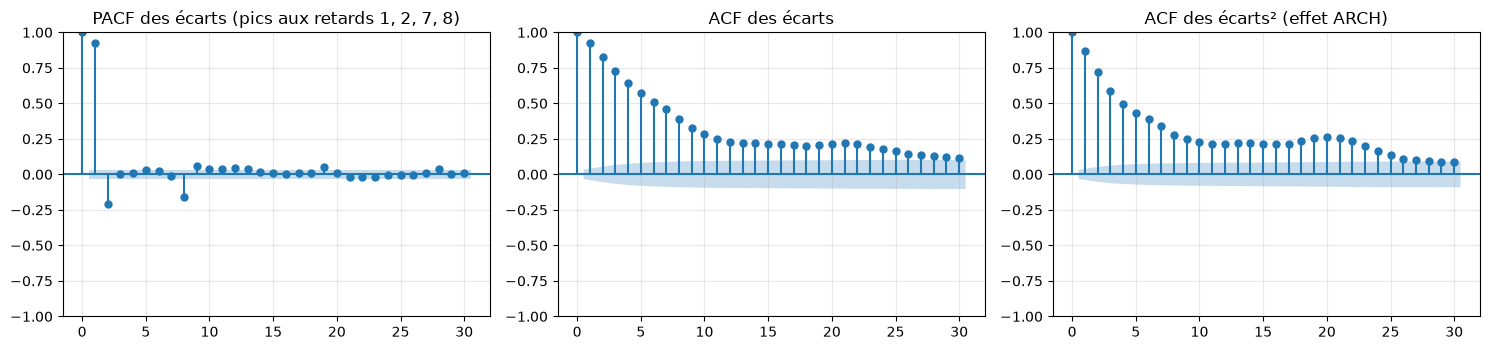

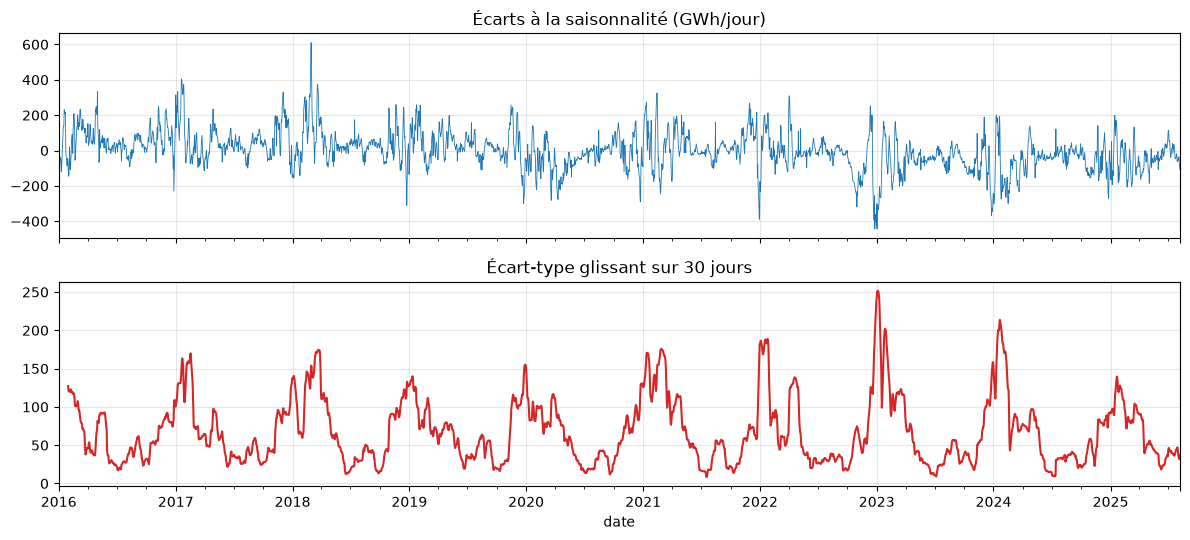

In [16]:
Xd = sm.add_constant(X_all.loc[dev.index])
seas_fit = sm.OLS(dev['conso_gwh'], Xd).fit()
seas_all = pd.Series(seas_fit.predict(sm.add_constant(X_all, has_constant='add')), index=df.index)
dev_all = (df['conso_gwh'] - seas_all)                 # écarts à la saisonnalité (apprentissage + test, paramètres figés sur l'apprentissage)
dev_train = dev_all.loc[dev.index]
print(f'R² de la saisonnalité calendrier : {seas_fit.rsquared:.3f} ; écart-type des écarts (apprentissage) : {dev_train.std():.1f} GWh')
ar_cands = {f'AR({p})': list(range(1, p + 1)) for p in [1, 2, 7, 8, 14, 21]}
ar_cands.update({'AR[1,2,7]': [1, 2, 7], 'AR[1,2,7,8]': [1, 2, 7, 8], 'AR[1,2,7,8,14]': [1, 2, 7, 8, 14], 'AR[1,2,3,7,8,14]': [1, 2, 3, 7, 8, 14]})
ar_bic = pd.Series({k: AutoReg(dev_train, lags=v, trend='c').fit().bic for k, v in ar_cands.items()}).sort_values()
display(ar_bic.round(1).to_frame('BIC'))
AR_LABEL = ar_bic.index[0]; AR_LAGS = ar_cands[AR_LABEL]
print('Moyenne autorégressive retenue (BIC minimal) :', AR_LABEL, AR_LAGS)
print('ARCH-LM sur les écarts bruts (H0 : variance constante) : p =', round(float(het_arch(dev_train - dev_train.mean(), nlags=7)[1]), 6))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
plot_pacf(dev_train, lags=30, method='ywm', ax=ax[0], title='PACF des écarts (pics aux retards 1, 2, 7, 8)')
plot_acf(dev_train, lags=30, ax=ax[1], title='ACF des écarts'); plot_acf(dev_train ** 2, lags=30, ax=ax[2], title='ACF des écarts² (effet ARCH)')
plt.tight_layout(); fig.savefig(FIG / 'garch_acf_pacf_ecarts.png', bbox_inches='tight'); plt.show()
ar_bic.to_csv(EXP / 'garch_choix_ar.csv', header=['BIC'])
vol = dev_train.rolling(30).std()
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
dev_train.plot(ax=ax[0], lw=.6); ax[0].set_title('Écarts à la saisonnalité (GWh/jour)')
vol.plot(ax=ax[1], color='C3'); ax[1].set_title('Écart-type glissant sur 30 jours')
plt.tight_layout(); fig.savefig(FIG / 'garch_ecarts_et_volatilite.png', bbox_inches='tight'); plt.show()

### Lecture
- La saisonnalité calendrier explique 82 % de la variance ; les écarts ont un écart-type de 106 GWh. Leur ACF² est positive et ARCH-LM rejette nettement (p ≈ 0) : **la variance n'est pas constante**, ce qui justifie le GARCH.
- Le PACF des écarts montre des pics aux retards **1, 2, 7 et 8** : mémoire courte + structure hebdomadaire. Le meilleur BIC est donc obtenu par un AR **creux** [1, 2, 7, 8, 14] (BIC 35 534), meilleur que AR(14) (35 598) et même AR(21) (35 565) : mieux vaut choisir les bons retards que beaucoup de retards.

### Comparaison GARCH(1,1) / ordres supérieurs / lois d'erreur
On compare GARCH(1,1), (2,1), (1,2), (2,2), avec erreurs normales puis Student-t (la loi t gère les queues épaisses). Critère : **BIC** (pénalise la complexité). La persistance α+β mesure la durée des épisodes de forte volatilité (proche de 1 = très persistante).

In [17]:
SC = 100.0                                              # on travaille en centaines de GWh pour la stabilité numérique de l'optimiseur

def fit_arch(series, spec, lags=None):
    am = arch_model(series / SC, mean='AR', lags=AR_LAGS if lags is None else lags, rescale=False, **spec)
    return am, am.fit(disp='off', options={'maxiter': 500})

garch_rows, garch_fits = [], {}
for dist in ['normal', 't']:
    for (p, q) in [(1, 1), (2, 1), (1, 2), (2, 2)]:
        spec = dict(vol='GARCH', p=p, q=q, dist=dist)
        am, r = fit_arch(dev_train, spec)
        pr = r.params
        persist = float(sum(pr[[n for n in pr.index if n.startswith(('alpha', 'beta'))]]))
        garch_fits[(p, q, dist)] = (spec, r)
        garch_rows.append({'modèle': f'GARCH({p},{q}) — {dist}', 'logL': r.loglikelihood, 'AIC': r.aic, 'BIC': r.bic, 'persistance α+β': persist,
                           'ν (ddl t)': pr.get('nu', np.nan), 'convergé': r.convergence_flag == 0})
garch_cmp = pd.DataFrame(garch_rows).set_index('modèle')
display(garch_cmp.round(5)); garch_cmp.to_csv(EXP / 'garch_comparaison.csv')
G_KEY = min(garch_fits, key=lambda k: garch_fits[k][1].bic)
g_spec, g_res = garch_fits[G_KEY]
GARCH_NAME = f'AR-GARCH({G_KEY[0]},{G_KEY[1]})-{G_KEY[2]}'
print('Meilleur BIC :', GARCH_NAME)
print(g_res.summary().tables[2])
print('Paramètres de variance (en unités de (100 GWh)²) :', g_res.params.filter(regex='omega|alpha|beta|nu').round(4).to_dict())

,logL,AIC,BIC,persistance α+β,ν (ddl t),convergé
modèle,,,,,,
"GARCH(1,1) — normal",-1145.45038,2308.90075,2364.32482,1.00000,NaN,True
"GARCH(2,1) — normal",-1145.45038,2310.90075,2372.48305,1.00000,NaN,True
"GARCH(1,2) — normal",-1133.77266,2287.54532,2349.12762,0.98501,NaN,True
"GARCH(2,2) — normal",-1133.77266,2289.54532,2357.28585,0.98502,NaN,True
"GARCH(1,1) — t",-873.82691,1767.65383,1829.23612,1.00000,4.07794,True
"GARCH(2,1) — t",-873.82691,1769.65382,1837.39435,1.00000,4.07794,True
"GARCH(1,2) — t",-857.36288,1736.72576,1804.46629,1.00000,4.09878,True
"GARCH(2,2) — t",-857.36288,1738.72576,1812.62452,1.00000,4.09880,True


Meilleur BIC : AR-GARCH(1,2)-t
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omega      5.1114e-03  1.247e-03      4.100  4.139e-05 [2.668e-03,7.555e-03]
alpha[1]       0.3370  2.620e-02     12.861  7.425e-38     [  0.286,  0.388]
beta[1]        0.1753  6.350e-02      2.760  5.775e-03   [5.082e-02,  0.300]
beta[2]        0.4877  6.584e-02      7.407  1.290e-13     [  0.359,  0.617]
Paramètres de variance (en unités de (100 GWh)²) : {'omega': 0.0051, 'alpha[1]': 0.337, 'beta[1]': 0.1753, 'beta[2]': 0.4877, 'nu': 4.0988}


### Lecture de la comparaison
- **Loi t contre normale** : la log-vraisemblance passe de ≈ −1 145 à ≈ −874 : les queues sont très épaisses (ν ≈ 4,1 degrés de liberté). Rester en loi normale serait une erreur.
- **GARCH(2,1) = GARCH(1,1)** (log-vraisemblance identique : le second terme ARCH est nul), mais **GARCH(1,2) améliore nettement** (+16,5 de log-vraisemblance pour un seul paramètre en plus ; BIC 1 804 contre 1 829) : la variance garde une mémoire plus longue que ce que permet un seul retard de σ². On retient **AR-GARCH(1,2)-t**.
- **Persistance** α + β ≈ 1,00 pour les lois t : quasi-**IGARCH**, c'est-à-dire que les épisodes de forte volatilité s'estompent très lentement. Cela reflète probablement que la volatilité est surtout **saisonnière** (forte l'hiver) et par régimes (2020, 2022), ce qu'un GARCH sans composante saisonnière traduit par une persistance extrême. C'est une limite du modèle, pas une propriété économique.

### Résidus standardisés
Si le GARCH est bien spécifié, les résidus standardisés z_t = ε_t / σ_t doivent être sans autocorrélation, et z²_t aussi (sinon il reste de la dynamique de variance non captée). On teste aussi leur normalité (Jarque-Bera) et la présence résiduelle d'effet ARCH.

,LB(z) p h=7,LB(z) p h=14,LB(z²) p h=7,LB(z²) p h=14,JB(z) p,kurtosis z,ARCH-LM(z) p
modèle,,,,,,,
"AR[1,2,7,8,14], variance constante (témoin)",0.8477,0.6952,0.0000,0.0000,0.0,7.3961,0.0000
"AR-GARCH(1,1) — normal",0.8884,0.9327,0.0001,0.0059,0.0,8.1157,0.0002
"AR-GARCH(1,1) — t",0.5889,0.5018,0.0000,0.0012,0.0,9.1037,0.0000
"AR-GARCH(1,2)-t (retenu)",0.7168,0.6245,0.0498,0.2589,0.0,10.1016,0.0602


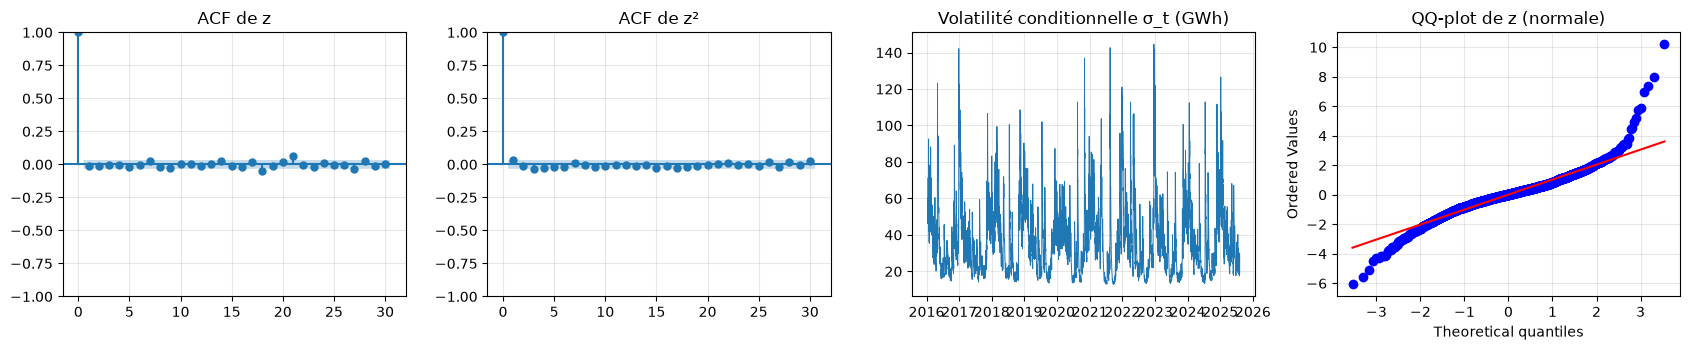

In [18]:
def garch_diag(res, label):
    z = res.std_resid.dropna()
    lb1 = acorr_ljungbox(z, lags=[7, 14], return_df=True); lb2 = acorr_ljungbox(z ** 2, lags=[7, 14], return_df=True)
    jb, jb_p, _, kurt = jarque_bera(z); _, lm_p, _, _ = het_arch(z, nlags=7)
    return {'modèle': label, 'LB(z) p h=7': lb1.loc[7, 'lb_pvalue'], 'LB(z) p h=14': lb1.loc[14, 'lb_pvalue'],
            'LB(z²) p h=7': lb2.loc[7, 'lb_pvalue'], 'LB(z²) p h=14': lb2.loc[14, 'lb_pvalue'],
            'JB(z) p': jb_p, 'kurtosis z': kurt, 'ARCH-LM(z) p': lm_p}

ctl_spec = dict(vol='Constant', dist='normal')                    # témoin : même moyenne AR, variance CONSTANTE
_, ctl_res = fit_arch(dev_train, ctl_spec)
diag_garch = pd.DataFrame([garch_diag(ctl_res, f'{AR_LABEL}, variance constante (témoin)'),
                           garch_diag(garch_fits[(1, 1, 'normal')][1], 'AR-GARCH(1,1) — normal'),
                           garch_diag(garch_fits[(1, 1, 't')][1], 'AR-GARCH(1,1) — t'),
                           garch_diag(g_res, GARCH_NAME + ' (retenu)')]).set_index('modèle')
display(diag_garch.round(4)); diag_garch.to_csv(EXP / 'garch_diagnostics.csv')
z = g_res.std_resid.dropna()
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
plot_acf(z, lags=30, ax=ax[0], title='ACF de z'); plot_acf(z ** 2, lags=30, ax=ax[1], title='ACF de z²')
ax[2].plot(g_res.conditional_volatility * SC, lw=.7); ax[2].set_title('Volatilité conditionnelle σ_t (GWh)')
stats.probplot(z, dist='norm', plot=ax[3]); ax[3].set_title('QQ-plot de z (normale)')
plt.tight_layout(); fig.savefig(FIG / 'garch_residus_standardises.png', bbox_inches='tight'); plt.show()

### Lecture des résidus standardisés
- **Moyenne bien spécifiée** : Ljung-Box sur z : p = 0,72 (h = 7) et 0,62 (h = 14), plus d'autocorrélation.
- **Variance** : sur z², le GARCH(1,2)-t donne p = 0,050 et 0,259 : l'effet ARCH est presque entièrement capté. À comparer au GARCH(1,1) (p = 2·10⁻⁵ et 0,001 avec loi t : insuffisant) et au **témoin à variance constante** (p ≈ 10⁻¹¹⁶ : l'effet ARCH est énorme sans GARCH). ARCH-LM sur z : p = 0,060 (non rejet à 5 %).
- **Normalité** : Jarque-Bera rejette encore (kurtosis de z ≈ 10) : même la loi t n'absorbe pas tous les jours extrêmes (jours fériés atypiques, vagues de froid).

### Prévision glissante : saisonnalité + AR + volatilité GARCH
Prévision de la consommation = saisonnalité calendrier (figée) + prévision AR de l'écart ; l'intervalle à 95 % utilise la variance conditionnelle prévue par le GARCH (elle varie donc selon la période, contrairement à ARIMA/VAR).
On calcule aussi le **témoin** (même moyenne AR, variance constante) pour isoler ce qu'apporte réellement le GARCH.

In [19]:
def arch_quantile(res, spec):
    if spec['dist'] == 't':
        nu = res.params['nu']
        return stats.t.ppf(1 - ALPHA / 2, nu) * np.sqrt((nu - 2) / nu)
    return stats.norm.ppf(1 - ALPHA / 2)

def wf_arch(res, spec, start, end, h=HORIZON):
    am_full = arch_model(dev_all / SC, mean='AR', lags=AR_LAGS, rescale=False, **spec)
    fixed = am_full.fix(res.params)                       # paramètres figés sur l'apprentissage, états actualisés à chaque origine
    q = arch_quantile(res, spec)
    fc = fixed.forecast(horizon=h, start=dev_all.index[start - 1], reindex=False)
    mean, var = fc.mean * SC, fc.variance * SC ** 2
    rows = []
    for s in range(start, end, h):
        steps = min(s + h, end) - s
        origin = dev_all.index[s - 1]
        for j in range(steps):
            date = dev_all.index[s + j]
            pt = seas_all[date] + mean.loc[origin].iloc[j]
            sd = np.sqrt(var.loc[origin].iloc[j])
            rows.append((origin, date, j + 1, df['conso_gwh'].iloc[s + j], pt, pt - q * sd, pt + q * sd))
    return to_frame(rows)

pred_garch = wf_arch(g_res, g_spec, n_train, len(df))
pred_ar_const = wf_arch(ctl_res, ctl_spec, n_train, len(df))
assert pred_garch['date'].tolist() == list(test.index) == pred_ar_const['date'].tolist()
print(GARCH_NAME, {k: round(float(v), 3) for k, v in forecast_metrics(pred_garch).items()})
print('Témoin variance constante', {k: round(float(v), 3) for k, v in forecast_metrics(pred_ar_const).items()})

AR-GARCH(1,2)-t {'n': 390.0, 'MSE': 5543.305, 'RMSE': 74.453, 'MAE': 48.612, 'MAPE (%)': 3.781, 'biais': -1.318, 'couverture_95': 0.959, 'largeur_moy_95': 300.098}
Témoin variance constante {'n': 390.0, 'MSE': 5485.239, 'RMSE': 74.062, 'MAE': 49.163, 'MAPE (%)': 3.84, 'biais': 3.58, 'couverture_95': 0.933, 'largeur_moy_95': 286.433}


### Lecture
Sur le test externe, le modèle **AR-GARCH(1,2)-t** obtient RMSE 74,5 GWh, MAE 48,6, MAPE 3,78 %, couverture 95,9 %. Le **témoin** (même moyenne, variance constante) obtient RMSE 74,1, MAE 49,2, couverture 93,3 %.
**Ce que le GARCH apporte réellement** : *pas* de meilleure prévision ponctuelle (l'écart de RMSE est nul à l'échelle de l'incertitude : c'est la moyenne AR + le calendrier qui font le travail), mais des **intervalles mieux calibrés** (95,9 % contre 93,3 % pour un nominal de 95 %), au prix d'une largeur un peu plus grande (300 contre 286 GWh). Un GARCH sert à quantifier le risque, pas à améliorer la moyenne.

## Étape 13 — Prophet (modèle additionnel)
Prophet (Meta) décompose la série en **tendance** (linéaire par morceaux, avec points de rupture) + **saisonnalités** (annuelle et hebdomadaire par séries de Fourier) + **jours fériés**. Il ne modélise pas l'autocorrélation à court terme : c'est un modèle « courbe », robuste mais moins précis à 1–7 jours.
Hyperparamètres comparés en **validation interne** (même règle) : flexibilité de la tendance (`changepoint_prior_scale`) et mode de saisonnalité (additif / multiplicatif). Jours fériés = colonne `ferie` de Fayfa (calendrier connu à l'avance).
Comme Prophet n'a pas d'« état » à actualiser, on **ré-ajuste** le modèle toutes les 7 jours sur l'historique disponible (fenêtre croissante) pour respecter le protocole h = 7.

In [20]:
holidays = pd.DataFrame({'holiday': 'ferie', 'ds': df.index[df['ferie'] == 1]})

def fit_prophet(upto, cps, mode):
    d = pd.DataFrame({'ds': df.index[:upto], 'y': df['conso_gwh'].iloc[:upto].to_numpy()})
    m = Prophet(changepoint_prior_scale=cps, seasonality_mode=mode, interval_width=1 - ALPHA, daily_seasonality=False, holidays=holidays)
    m.fit(d)
    return m

def prophet_predict(m, dates):
    np.random.seed(SEED)
    out = m.predict(pd.DataFrame({'ds': dates}))
    return out['yhat'].to_numpy(), out['yhat_lower'].to_numpy(), out['yhat_upper'].to_numpy()

def wf_prophet(start, end, cps, mode, h=HORIZON):
    rows = []
    for s in range(start, end, h):
        e = min(s + h, end)
        m = fit_prophet(s, cps, mode)
        yh, lo, hi = prophet_predict(m, df.index[s:e])
        for j in range(e - s):
            rows.append((df.index[s - 1], df.index[s + j], j + 1, df['conso_gwh'].iloc[s + j], yh[j], lo[j], hi[j]))
    return to_frame(rows)

prophet_val_rows = []
for cps in [0.05, 0.5]:
    for mode in ['additive', 'multiplicative']:
        m = forecast_metrics(wf_prophet(n_est, n_train, cps, mode))
        prophet_val_rows.append({'changepoint_prior_scale': cps, 'seasonality_mode': mode, 'RMSE validation': m['RMSE'], 'MAE validation': m['MAE']})
prophet_val = pd.DataFrame(prophet_val_rows)
display(prophet_val.round(3)); prophet_val.to_csv(EXP / 'prophet_validation_interne.csv', index=False)
best = prophet_val.loc[prophet_val['RMSE validation'].idxmin()]
CPS, MODE = float(best['changepoint_prior_scale']), str(best['seasonality_mode'])
print('Prophet retenu :', CPS, MODE)

,changepoint_prior_scale,seasonality_mode,RMSE validation,MAE validation
0,0.05,additive,60.276,45.075
1,0.05,multiplicative,57.132,41.937
2,0.50,additive,51.902,38.831
3,0.50,multiplicative,52.484,38.345


Prophet retenu : 0.5 additive


### Lecture
La tendance **flexible** (changepoint_prior_scale = 0,5) est nettement meilleure en validation (RMSE 51,6) que la tendance rigide par défaut (60,3) : la série a des ruptures (confinements de 2020, sobriété 2022-23) que la tendance rigide suit mal. Mode additif retenu (écart minime avec le multiplicatif).

,n,LB p (h=7),LB p (h=14),JB p,asymétrie,kurtosis,ARCH-LM p
modèle/série,,,,,,,
"Prophet (cps=0.5, additive) — résidus",3506,0.0,0.0,0.0,0.4082,4.9411,0.0


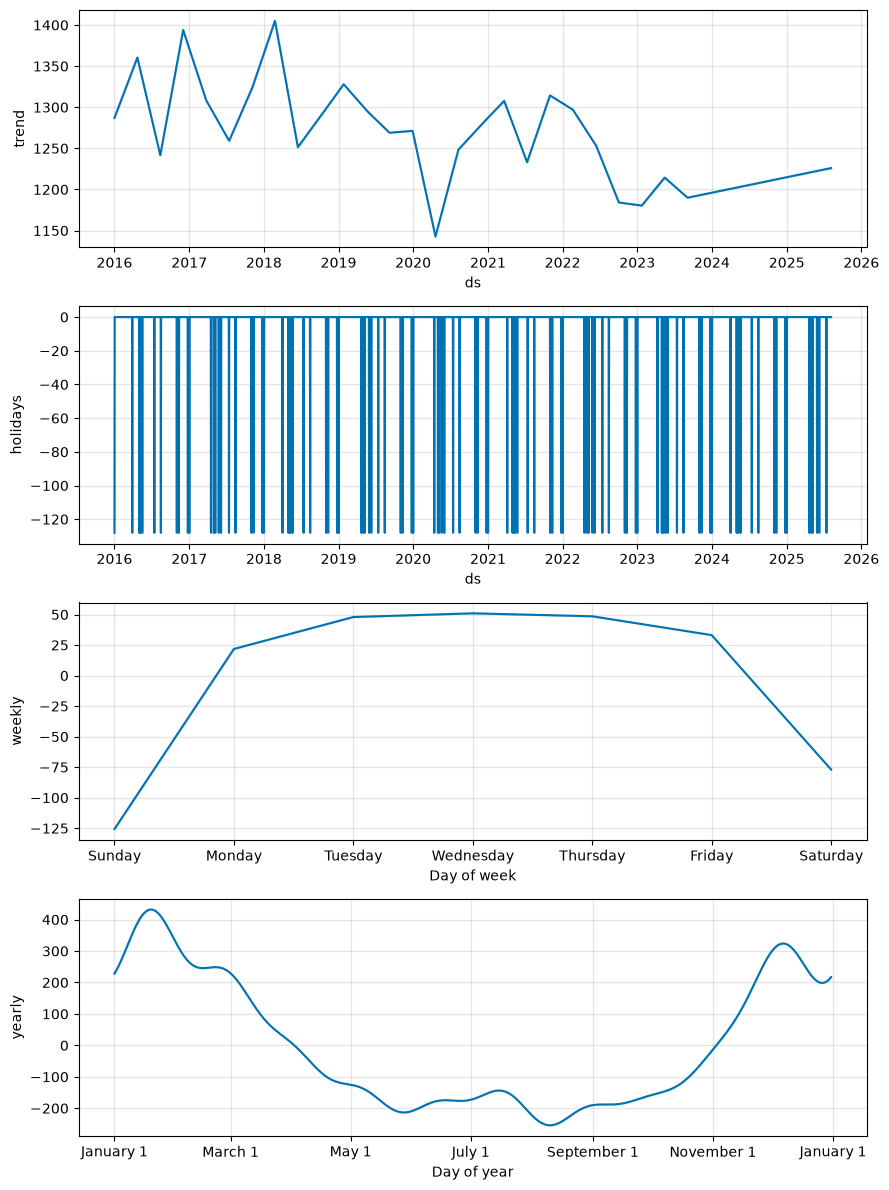

Prophet (ré-ajusté toutes les 7 j) : {'n': 390, 'MSE': 10361.039, 'RMSE': 101.789, 'MAE': 75.063, 'MAPE (%)': 5.912, 'biais': -1.37, 'couverture_95': 0.885, 'largeur_moy_95': 332.149}
Prophet (ajustement unique, h ≤ 390 j) : {'n': 390, 'MSE': 9519.415, 'RMSE': 97.567, 'MAE': 69.071, 'MAPE (%)': 5.383, 'biais': 7.328, 'couverture_95': 0.974, 'largeur_moy_95': 890.708}


In [21]:
m_dev = fit_prophet(n_train, CPS, MODE)
fitted = m_dev.predict(pd.DataFrame({'ds': dev.index}))
res_prophet = dev['conso_gwh'].to_numpy() - fitted['yhat'].to_numpy()
diag_prophet = pd.DataFrame([diagnostics(res_prophet, f'Prophet (cps={CPS}, {MODE}) — résidus')]).set_index('modèle/série')
display(diag_prophet.round(4)); diag_prophet.to_csv(EXP / 'prophet_diagnostics.csv')
fig = m_dev.plot_components(fitted); fig.savefig(FIG / 'prophet_composantes.png', bbox_inches='tight'); plt.show()
pred_prophet = wf_prophet(n_train, len(df), CPS, MODE)
assert pred_prophet['date'].tolist() == list(test.index)
# Variante « ajustement unique » : un seul ajustement sur l'apprentissage, prévision directe jusqu'à 390 jours
yh, lo, hi = prophet_predict(m_dev, test.index)
pred_prophet_fixe = to_frame([(dev.index[-1], d, i + 1, test['conso_gwh'].iloc[i], yh[i], lo[i], hi[i]) for i, d in enumerate(test.index)])
print('Prophet (ré-ajusté toutes les 7 j) :', {k: round(v, 3) for k, v in forecast_metrics(pred_prophet).items()})
print('Prophet (ajustement unique, h ≤ 390 j) :', {k: round(v, 3) for k, v in forecast_metrics(pred_prophet_fixe).items()})

### Lecture
- Diagnostics : les résidus de Prophet sont très autocorrélés (Ljung-Box p ≈ 0) et ont un effet ARCH : normal, **Prophet n'a pas de mémoire à court terme** (pas de terme autorégressif).
- **Test externe** : RMSE 101,9 GWh (ré-ajusté chaque semaine) et 97,8 (ajustement unique), soit nettement moins bien que le SARIMA de Yosra (82,4) et juste mieux que le naïf « dernière valeur » (109,1).
- **Intervalles** : couverture de 88,5 % seulement en version hebdomadaire (trop étroits : Prophet ne tient compte que de l'incertitude de tendance et du bruit, pas de l'autocorrélation) ; la version à ajustement unique a 96,9 % de couverture mais avec une largeur de 836 GWh, car elle prévoit jusqu'à 390 jours — elle n'est pas comparable au protocole h = 7.
Prophet reste utile comme modèle de **tendance + saisonnalité** et pour ses composantes (figure ci-dessus), pas pour la prévision à 7 jours.

## Étape 14 — Évaluation commune sur le test externe
Tous les modèles de ce notebook, plus les références de Yosra (SARIMA retenu, naïf saisonnier, naïf dernière valeur, relus depuis `exports/predictions_test.csv`) : mêmes 390 dates, mêmes observations, mêmes métriques.

In [22]:
ref = pd.read_csv('exports/predictions_test.csv', parse_dates=['origine', 'date'])
models = {f'VAR({P_VAR})': pred_var, f'VECM(k={K_VECM}, r=1)': pred_vecm,
          GARCH_NAME: pred_garch, f'{AR_LABEL} variance constante (témoin)': pred_ar_const, 'Prophet (hebdo)': pred_prophet, 'Prophet (unique)': pred_prophet_fixe}
for name in ref['modele'].unique():
    sub = ref[ref['modele'] == name].sort_values('date')[COLS].reset_index(drop=True)
    assert sub['date'].tolist() == list(test.index) and np.allclose(sub['observe'], test['conso_gwh'])
    models[name + ' (Yosra)'] = sub
metrics = pd.DataFrame({k: forecast_metrics(v) for k, v in models.items()}).T
display(metrics.round(3).sort_values('RMSE')); metrics.sort_values('RMSE').to_csv(EXP / 'metriques_test.csv')
by_h = pd.DataFrame({k: v.groupby('horizon').apply(lambda g: np.sqrt(np.mean((g['observe'] - g['prevision'])**2))) for k, v in models.items() if v['horizon'].max() <= HORIZON})
display(by_h.round(1)); by_h.to_csv(EXP / 'rmse_par_horizon.csv')

,n,MSE,RMSE,MAE,MAPE (%),biais,couverture_95,largeur_moy_95
"AR[1,2,7,8,14] variance constante (témoin)",390.0,5485.239,74.062,49.163,3.840,3.580,0.933,286.433
"AR-GARCH(1,2)-t",390.0,5543.305,74.453,48.612,3.781,-1.318,0.959,300.098
VAR(3),390.0,6234.262,78.957,54.670,4.306,3.052,0.931,277.975
SARIMA_211_011 (Yosra),390.0,6786.816,82.382,53.116,4.133,1.246,0.944,346.749
"VECM(k=12, r=1)",390.0,7667.095,87.562,58.706,4.606,-7.209,0.913,293.854
Prophet (unique),390.0,9519.415,97.567,69.071,5.383,7.328,0.974,890.708
Prophet (hebdo),390.0,10361.039,101.789,75.063,5.912,-1.370,0.885,332.149
naif_derniere_valeur (Yosra),390.0,11909.588,109.131,76.625,6.458,42.319,NaN,NaN
naif_saisonnier (Yosra),390.0,12979.433,113.927,76.660,5.967,-1.060,NaN,NaN


,VAR(3),"VECM(k=12, r=1)","AR-GARCH(1,2)-t","AR[1,2,7,8,14] variance constante (témoin)",Prophet (hebdo),SARIMA_211_011 (Yosra),naif_saisonnier (Yosra),naif_derniere_valeur (Yosra)
horizon,,,,,,,,
1,33.4,34.2,37.9,38.4,99.6,33.8,106.0,35.8
2,59.2,62.7,52.6,52.5,96.4,60.7,113.0,62.9
3,79.6,86.4,73.6,72.1,105.8,72.5,119.0,129.9
4,86.5,97.5,78.3,76.0,102.9,82.5,118.6,165.1
5,80.8,94.2,76.0,77.4,96.4,90.3,111.0,96.5
6,93.8,102.7,90.2,90.3,104.0,101.2,113.6,106.3
7,100.0,111.0,96.2,95.7,106.9,111.4,115.8,115.8


### Lecture de l'évaluation commune
Classement par RMSE sur le test (390 jours) : AR creux à variance constante (74,1) ≈ **AR-GARCH(1,2)-t (74,5)** < **VAR(3) (79,0)** < SARIMA de Yosra (82,4) < **VECM (87,6)** < **Prophet (97,8 à 101,9)** < naïfs (109,1 et 113,9).
Par horizon, l'erreur croît de ≈ 33–38 GWh à h = 1 jusqu'à ≈ 96–111 GWh à h = 7. À h = 1 tous les modèles dynamiques (VAR, SARIMA, naïf « dernière valeur ») sont à égalité (≈ 33–36) : la persistance de la consommation suffit ; l'avantage des modèles AR/GARCH apparaît à h ≥ 4.
**Précautions de lecture.** (1) Les modèles de ce notebook utilisent des régresseurs de calendrier (jour férié, cycle annuel) que le SARIMA de Yosra n'a pas : la comparaison les avantage, elle ne prouve pas que le VAR ou le GARCH soient intrinsèquement meilleurs. (2) Les écarts de quelques GWh entre modèles voisins ne sont pas testés ici : c'est le rôle du test de Diebold-Mariano d'Anas. (3) Les prévisions à 7 jours ci-dessous sont des prévisions pour le 1er–7 septembre 2026, pas pour octobre.

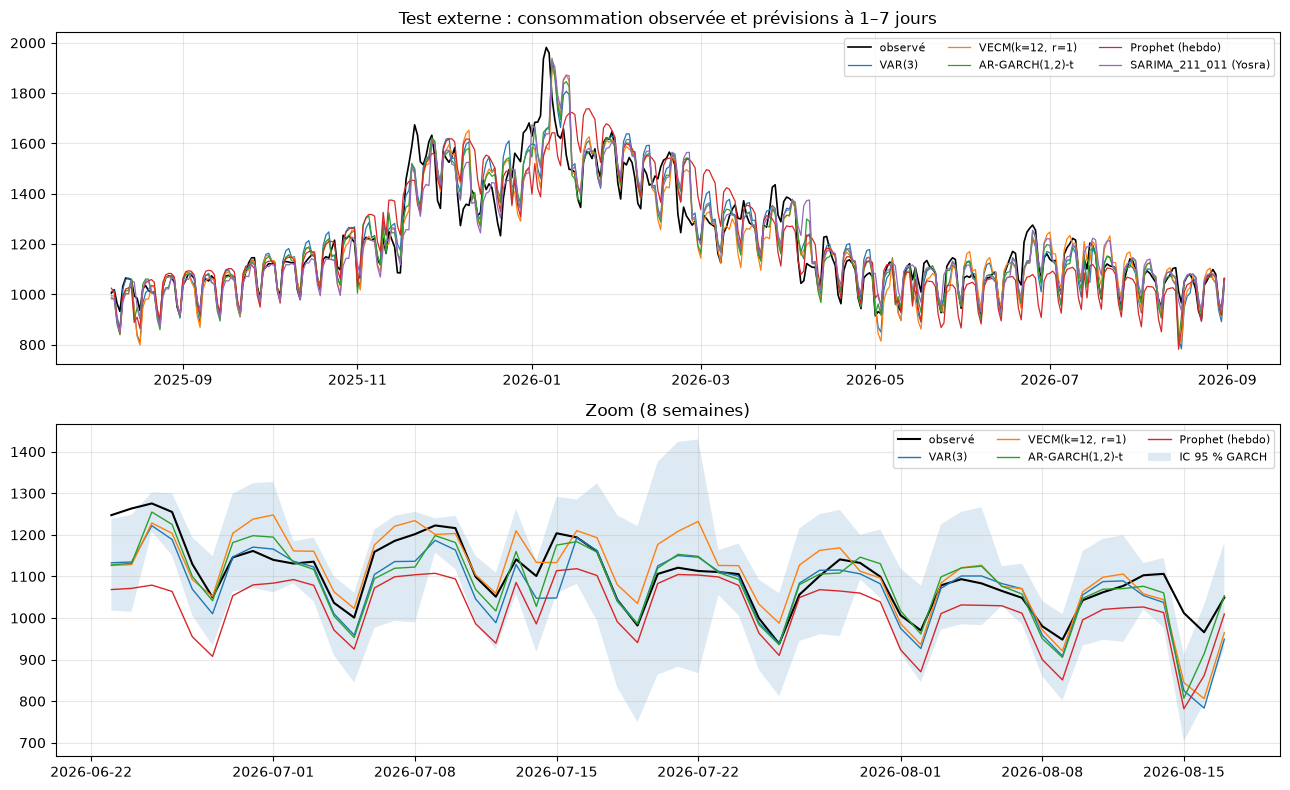

In [23]:
main = [f'VAR({P_VAR})', f'VECM(k={K_VECM}, r=1)', GARCH_NAME, 'Prophet (hebdo)', 'SARIMA_211_011 (Yosra)']
fig, ax = plt.subplots(2, 1, figsize=(13, 8))
ax[0].plot(test.index, test['conso_gwh'], 'k', lw=1.2, label='observé')
for k in main: ax[0].plot(models[k]['date'], models[k]['prevision'], lw=.9, label=k)
ax[0].set_title('Test externe : consommation observée et prévisions à 1–7 jours'); ax[0].legend(ncol=3, fontsize=8)
zoom = slice(len(test) - 70, len(test) - 14)
ax[1].plot(test.index[zoom], test['conso_gwh'].iloc[zoom], 'k', lw=1.5, label='observé')
for k in main[:4]: ax[1].plot(models[k]['date'].iloc[zoom], models[k]['prevision'].iloc[zoom], lw=1, label=k)
ax[1].fill_between(models[main[2]]['date'].iloc[zoom], models[main[2]]['borne_inferieure_95'].iloc[zoom], models[main[2]]['borne_superieure_95'].iloc[zoom], alpha=.15, label='IC 95 % GARCH')
ax[1].set_title('Zoom (8 semaines)'); ax[1].legend(ncol=3, fontsize=8)
plt.tight_layout(); fig.savefig(FIG / 'ghada_comparaison_test.png', bbox_inches='tight'); plt.show()

## Étape 15 — Livrables partagés (`forecasts/<modèle>.csv`) et prévisions à 7 jours
Format convenu par le groupe : `date, prevision, borne_inferieure_95, borne_superieure_95`. Un fichier par modèle, sur les 390 jours du test (prévisions à 1–7 jours depuis chaque origine).
Puis, comme Yosra, on ré-estime chaque modèle sur **toutes** les données et on prévoit les 7 jours **après** la dernière observation (1er–7 septembre 2026).

In [24]:
share = {'var': pred_var, 'vecm': pred_vecm, 'garch': pred_garch, 'prophet': pred_prophet}
for name, p in share.items():
    out = p[['date', 'prevision', 'borne_inferieure_95', 'borne_superieure_95']].copy()
    out['date'] = out['date'].dt.strftime('%Y-%m-%d')
    out.to_csv(FC / f'{name}.csv', index=False)
    print(f'forecasts/{name}.csv : {len(out)} lignes')
# détail (origine, horizon, observé) pour les contrôles
pd.concat({k: v for k, v in share.items()}, names=['modele']).reset_index(level=0).to_csv(EXP / 'predictions_test_detail.csv', index=False)

forecasts/var.csv : 390 lignes
forecasts/vecm.csv : 390 lignes
forecasts/garch.csv : 390 lignes
forecasts/prophet.csv : 390 lignes


In [25]:
future_idx = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=HORIZON, freq='D')
ext_idx = df.index.append(future_idx)
X_ext = build_exog(ext_idx)
N = len(df)
Xf = X_ext.iloc[N:]
rows = {}
# VAR (ordre figé, réestimé sur toutes les données)
v_all = VAR(df[ENDOG], exog=X_ext.iloc[:N]).fit(P_VAR)
fc, lo, hi = v_all.forecast_interval(df[ENDOG].iloc[-P_VAR:].to_numpy(), steps=HORIZON, alpha=ALPHA, exog_future=Xf.to_numpy())
rows['var'] = (fc[:, 0], lo[:, 0], hi[:, 0])
# VECM
vc_all = fit_vecm(df[ENDOG], K_VECM, X_ext.iloc[:N])
fc, lo, hi = vecm_forecast_block(vc_all, df[ENDOG], X_ext, N, HORIZON)
rows['vecm'] = (fc[:, 0], lo[:, 0], hi[:, 0])
# GARCH : saisonnalité + AR-GARCH réestimés sur toutes les données (mêmes ordres)
s_fit = sm.OLS(df['conso_gwh'], sm.add_constant(X_ext.iloc[:N])).fit()
s_ext = pd.Series(s_fit.predict(sm.add_constant(X_ext, has_constant='add')), index=ext_idx)
d_all = df['conso_gwh'] - s_ext.iloc[:N]
_, r_f = fit_arch(d_all, g_spec)
fcg = r_f.forecast(horizon=HORIZON, reindex=False)
mean_f, var_f = fcg.mean.iloc[-1].to_numpy() * SC, fcg.variance.iloc[-1].to_numpy() * SC ** 2
qf = arch_quantile(r_f, g_spec)
pt = s_ext.iloc[N:].to_numpy() + mean_f
rows['garch'] = (pt, pt - qf * np.sqrt(var_f), pt + qf * np.sqrt(var_f))
# Prophet
m_all = fit_prophet(N, CPS, MODE)
rows['prophet'] = prophet_predict(m_all, future_idx)
final = []
for name, (pt, lo, hi) in rows.items():
    out = pd.DataFrame({'date': future_idx.strftime('%Y-%m-%d'), 'prevision': pt, 'borne_inferieure_95': lo, 'borne_superieure_95': hi})
    out.to_csv(EXP / f'previsions_7j_{name}.csv', index=False)
    final.append(out.assign(modele=name))
final = pd.concat(final)
display(final.pivot(index='date', columns='modele', values='prevision').round(1))
print('Dernière observation :', df.index[-1].date(), '— dates prévues :', future_idx[0].date(), '→', future_idx[-1].date(), '(pas des dates d\'octobre)')

modele,garch,prophet,var,vecm
date,,,,
2026-09-01,1079.1,1090.1,1097.5,1100.6
2026-09-02,1082.3,1094.8,1103.0,1110.2
2026-09-03,1082.2,1094.2,1099.0,1108.5
2026-09-04,1064.4,1080.2,1083.4,1086.7
2026-09-05,954.0,972.5,973.1,977.7
2026-09-06,907.0,925.6,923.7,933.0
2026-09-07,1049.7,1071.2,1067.2,1071.6


Dernière observation : 2026-08-31 — dates prévues : 2026-09-01 → 2026-09-07 (pas des dates d'octobre)
